# Session 13: training a 20M LLM with and without reversibility

The assignment:

1. Train a 20M LLM on 50M tokens with a fixed batch size.
2. Train again with reversibility. Report which variant worked (midpoint, Euler, …).
3. Train again with reversibility, pushed to the maximum batch size.
4. Report final loss, speed (tokens/s), peak memory and other findings.

Everything ran on one Apple M1 Pro (32 GB unified memory, PyTorch MPS backend, fp32). The 50M-token runs are
done by `python -m rev.experiments`, which saves each run to `results/`. This notebook reads
those results and makes every other measurement live.

| piece | where |
|---|---|
| data, tokenizer | `rev/data.py`: TinyStories, byte-level BPE with 8,192 tokens |
| model, the three rules, reversible backward | `rev/model.py` |
| training loop, peak-memory sampler | `rev/train.py` |
| run order, sweep, max-batch search | `rev/experiments.py` |
| drift, memory sweeps, timing | `rev/analysis.py` |
| tests | `tests/test_rev.py` |

In [1]:
import json, math, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from rev.data import load
from rev.model import GPT, GPTConfig
from rev.train import RunConfig, measure_peak, peak_lr
from rev import analysis as A
from rev.experiments import SWEEP, BUDGET, FIXED_BATCH, load as R

GiB = 2 ** 30
ART = ROOT / "submission_artifacts"; ART.mkdir(exist_ok=True)
NUM = {}                                  # every number the README quotes
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEV)

torch 2.14.1 | device mps


## 1. Data and model

TinyStories (the GPT-4 version), first 270 MB of the training file. A byte-level BPE tokenizer with 8,192 tokens
was trained on it. With GPT-2's 50,257-token vocabulary the embedding alone would hold 19M of the 20M parameters.
The training stream is 55M tokens, read in the same order by every run. Validation uses the separate TinyStories
validation file.

In [2]:
train, valid = load("train"), load("valid")
cfg = RunConfig()
m = GPT(cfg.gpt())
emb = m.tok.weight.numel() + m.pos.weight.numel()
blocks = sum(p.numel() for p in m.blocks.parameters())
print(f"train tokens {len(train):,}   valid tokens {len(valid):,}")
print(f"model: d={cfg.d}, layers={cfg.n_layer}, heads={cfg.n_head}, seq={cfg.seq}, vocab=8192 (tied head)")
print(f"parameters {m.n_params():,} = embeddings {emb:,} + blocks {blocks:,} + final norm {m.n_params()-emb-blocks:,}")
NUM["params"] = m.n_params()
del m

train tokens 55,000,000   valid tokens 2,000,000
model: d=384, layers=10, heads=6, seq=256, vocab=8192 (tied head)
parameters 20,954,880 = embeddings 3,244,032 + blocks 17,710,080 + final norm 768


## 2. The three rules, and why the reversible backward gives the same gradients

Write $p^\ell$ for the residual stream entering layer $\ell$. $f_\ell(p) = A(p) + M(p + A(p))$ is the whole block's
update: attention, then the feed-forward network.

| rule | forward | inverse (what the backward pass runs) | stored for backward |
|---|---|---|---|
| standard | $p^{\ell+1} = p^\ell + f_\ell(p^\ell)$ | none: $p^\ell$ sits inside $f_\ell(p^\ell)$ | every layer's activations |
| midpoint | $p^{\ell+1} = a\,p^{\ell-1} + (1-a)\,p^\ell + 2h\,f_\ell(p^\ell)$ | $p^{\ell-1} = \big(p^{\ell+1} - (1-a)p^\ell - 2h f_\ell(p^\ell)\big)/a$ | $p^{L-1}, p^L$ |
| Euler, two-stream coupling | $y_1 = x_1 + h\,A_\ell(x_2)$, $y_2 = x_2 + h\,M_\ell(y_1)$ | $x_2 = y_2 - h M_\ell(y_1)$, $x_1 = y_1 - h A_\ell(x_2)$ | $x_1^L, x_2^L$ |

**Midpoint.** $a = 1$ is the course's rule. $a < 1$ is the "blend" form I tested in the sweep. The
inverse evaluates $f_\ell$ at $p^\ell$, which the backward pass already holds, so no iteration is needed.

**Why "Euler" needs two streams.** A plain Euler step $p^{\ell+1} = p^\ell + h f(p^\ell)$ is the ordinary residual
block. Undoing it means solving $p = p^{\ell+1} - h f(p)$ for $p$, which needs fixed-point iteration. Splitting the
stream in two (RevNet, Reformer) makes each half-step an Euler step whose inverse is a single subtraction. It is
the standard way to make an Euler-type update exactly invertible.

The reversible backward (`_Reversible` in `rev/model.py`) does this:

1. Run the forward pass under `no_grad` and save the top two states.
2. Then, for each layer from the top: rebuild its input, recompute the layer with gradients on, and backpropagate
   through it.

The check below runs it against ordinary autograd on the same rule in float64.

In [3]:
torch.manual_seed(0)
g = torch.Generator().manual_seed(1)
idx, y = torch.randint(0, 64, (3, 16), generator=g), torch.randint(0, 64, (3, 16), generator=g)
rows = []
for rule, h, blend in [("midpoint", 0.5, 1.0), ("midpoint", 0.25, 0.5), ("euler", 1.0, 1.0)]:
    torch.manual_seed(0)
    m = GPT(GPTConfig(vocab=64, seq=16, d=32, n_head=4, n_layer=8, rule=rule, h=h, blend=blend)).double()
    agree = A.gradient_agreement(m, idx, y)
    rows.append((rule, h, blend, agree["rel_err"], max(A.reconstruction(m, idx))))
    print(f"{rule:8s} h={h:<5} a={blend:<4}  grad rel. error {agree['rel_err']:.1e}   worst rebuilt state rel. error {rows[-1][-1]:.1e}")

midpoint h=0.5   a=1.0   grad rel. error 2.2e-16   worst rebuilt state rel. error 1.3e-16
midpoint h=0.25  a=0.5   grad rel. error 1.1e-15   worst rebuilt state rel. error 8.4e-15


euler    h=1.0   a=1.0   grad rel. error 1.6e-16   worst rebuilt state rel. error 1.5e-16


In float64 the reversible gradients match stored autograd to about 1e-15. The memory saving
costs nothing in correctness: the gradient is the same function. What remains is floating-point
error in the rebuilt states, measured on the trained models in Section 7.

## 3. Choosing the variant: a short sweep over step size and blend

Every candidate trained for 5M tokens at the fixed batch of 64 × 256. The sweep used the stored-activation form
of each rule, which is faster and has the same maths (Section 2). It covered:
- the midpoint rule at h = 0.125, 0.25, 0.5 and 1;
- the course's quoted Lightning LM setting, h = 0.25 with blend a = 0.5;
- the Euler coupling at h = 0.5 and 1;
- the standard model as the reference.

run                                 val loss train loss max grad norm
sweep_standard                        2.7813     2.7771          0.74 
sweep_midpoint_h0.125                 2.9016     2.9026          0.86 
sweep_midpoint_h0.25                  2.7808     2.7802          0.78 
sweep_midpoint_h0.5                   2.7706     2.7660          0.81 
sweep_midpoint_h1.0                   2.7765     2.7766          1.08 
sweep_midpoint_h0.25_blend0.5         2.7872     2.7833          0.88 
sweep_euler_h0.5                      2.7599     2.7516          0.85 
sweep_euler_h1.0                      2.8367     2.8325          1.44 


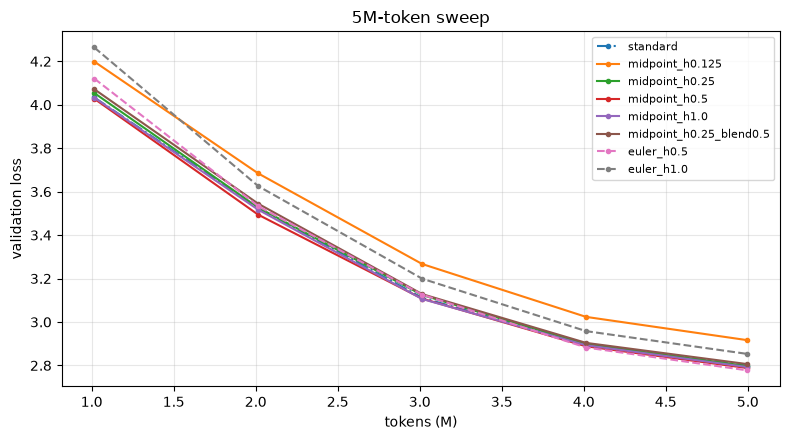

chosen (h, blend): {'midpoint': (0.5, 1.0), 'euler': (0.5, 1.0)}


In [4]:
rows = []
for name, (rule, h, blend) in SWEEP.items():
    log = R(name)
    ev = log["evals"]
    gmax = max(r["gnorm"] for r in log["train"])
    rows.append(dict(name=name, rule=rule, h=h, blend=blend, val=log["final_val_loss"], train=log["final_train_loss"],
                     gnorm_max=gmax, diverged=log["diverged"]))
print(f"{'run':34s} {'val loss':>9s} {'train loss':>10s} {'max grad norm':>13s}")
for r in rows:
    print(f"{r['name']:34s} {r['val']:9.4f} {r['train']:10.4f} {r['gnorm_max']:13.2f} {'DIVERGED' if r['diverged'] else ''}")
NUM["sweep"] = rows

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in SWEEP:
    ev = R(name)["evals"]
    ax.plot([e["tokens"] / 1e6 for e in ev], [e["val_loss"] for e in ev], marker="o", ms=3,
            label=name.replace("sweep_", ""), ls="--" if "euler" in name else ("-." if "standard" in name else "-"))
ax.set(xlabel="tokens (M)", ylabel="validation loss", title="5M-token sweep", ylim=(None, None))
ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "sweep.png", dpi=130); plt.show()

from rev.experiments import best
chosen = {r: best(r) for r in ("midpoint", "euler")}
print("chosen (h, blend):", chosen)
NUM["chosen"] = chosen

In [5]:
# How sensitive is each rule to h? (the course: "only marginally stable")
for rule in ("midpoint", "euler"):
    rs = [r for r in rows if r["rule"] == rule and r["blend"] == 1.0]
    spread = max(r["val"] for r in rs) - min(r["val"] for r in rs)
    print(f"{rule:8s}: val loss across h = " + ", ".join(f"h={r['h']}: {r['val']:.3f}" for r in rs) + f"   spread {spread:.3f}")

midpoint: val loss across h = h=0.125: 2.902, h=0.25: 2.781, h=0.5: 2.771, h=1.0: 2.777   spread 0.131
euler   : val loss across h = h=0.5: 2.760, h=1.0: 2.837   spread 0.077


## 4. Fixed batch: standard against both reversible variants, 50M tokens

All three runs use batch 64 × 256 = 16,384 tokens per step, which makes 3,051 steps. They share the same data
order, the same seed and the same schedule: AdamW, peak lr 1.5e-3, warmup over 1M tokens, cosine decay to 10%,
weight decay 0.1, clipping at 1.0.

- **Speed** is training tokens / seconds spent inside the training step. Evaluation is excluded.
- **Peak memory** is the largest allocated byte count during one full training step: weights, gradients, Adam
  state, activations and the loss.
  - MPS has no `max_memory_allocated`, so `Peak` in `rev/train.py` samples the allocated count after every aten op,
    forward and backward.
  - My first sampler only sampled at module boundaries and parameter gradients. It missed the logits, their
    log-softmax and their gradient, which are created inside `cross_entropy`, so it under-reported, by about half at
    large batch. That made the first max-batch search run out of memory.
  - The runs below were re-measured with the per-op sampler at their exact configs
    (`tools/remeasure_peaks.py`); the old figure is kept in the JSON as `peak_bytes_module_hooks`.

run                      batch     h  val loss train loss   tok/s  peak GiB  minutes
standard                    64  0.50    1.6017     1.5491   16068      6.47     51.9
midpoint (reversible)       64  0.50    1.6497     1.5984   13067      1.85     63.8
euler (reversible)          64  0.50    1.6383     1.5906   13244      1.88     62.9
midpoint (reversible): peak 3.49x smaller, speed 0.81x of standard, val loss +0.0480
euler (reversible): peak 3.45x smaller, speed 0.82x of standard, val loss +0.0366


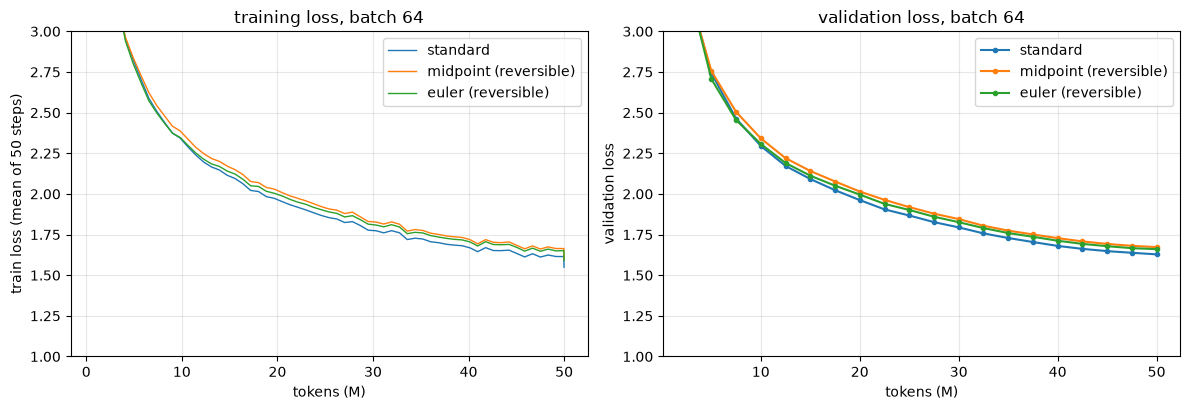

In [6]:
MAIN = {"standard": R("main_standard"), "midpoint (reversible)": R("main_midpoint_rev"), "euler (reversible)": R("main_euler_rev")}
def row(log):
    return dict(val=log["final_val_loss"], train=log["final_train_loss"], tok_s=log["tok_per_s"],
                peak_gib=log["peak_bytes"] / GiB, minutes=log["train_seconds"] / 60, steps=log["steps"],
                batch=log["config"]["batch"], h=log["config"]["h"], blend=log["config"]["blend"], tokens=log["tokens_seen"])
print(f"{'run':24s} {'batch':>5s} {'h':>5s} {'val loss':>9s} {'train loss':>10s} {'tok/s':>7s} {'peak GiB':>9s} {'minutes':>8s}")
NUM["main"] = {}
for k, log in MAIN.items():
    r = row(log); NUM["main"][k] = r
    print(f"{k:24s} {r['batch']:5d} {r['h']:5.2f} {r['val']:9.4f} {r['train']:10.4f} {r['tok_s']:7.0f} {r['peak_gib']:9.2f} {r['minutes']:8.1f}")
std = NUM["main"]["standard"]
for k in list(MAIN)[1:]:
    r = NUM["main"][k]
    print(f"{k}: peak {std['peak_gib']/r['peak_gib']:.2f}x smaller, speed {r['tok_s']/std['tok_s']:.2f}x of standard, "
          f"val loss {r['val']-std['val']:+.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k, log in MAIN.items():
    tr = log["train"]
    ax[0].plot([t["tokens"] / 1e6 for t in tr], [t["loss"] for t in tr], label=k, lw=1)
    ev = log["evals"]
    ax[1].plot([e["tokens"] / 1e6 for e in ev], [e["val_loss"] for e in ev], marker="o", ms=3, label=k)
ax[0].set(xlabel="tokens (M)", ylabel="train loss (mean of 50 steps)", ylim=(1.0, 3.0), title="training loss, batch 64")
ax[1].set(xlabel="tokens (M)", ylabel="validation loss", ylim=(1.0, 3.0), title="validation loss, batch 64")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "loss_fixed_batch.png", dpi=130); plt.show()

## 5. Reversibility pushed to the maximum batch

**The budget.** A 16 GiB card. That is the memory of a Colab T4, the GPU the assignment names. It also keeps the
32 GB Mac out of swap; MPS would allow about 25 GiB here.

**The search** (`max_batch` in `rev/experiments.py`):
1. Peak memory is linear in batch size, so fit it from two measured batches.
2. Jump to the predicted maximum.
3. Measure there, and step by 64 until the largest batch whose measured peak fits is found.

The same search runs for the standard model and for the winning rule with stored activations. Those two only
measure; they don't train. Comparing the three shows how many more samples reversibility fits.

**The run.** The winning variant trains for the same 50M tokens at that batch. Its learning rate scales with
$\sqrt{\text{batch}/64}$, capped at 6e-3. Warmup is at least 10 steps.

In [7]:
S = json.loads((ROOT / "results" / "maxbatch_search.json").read_text())
print(f"winner at the fixed batch: {S['rule']} (h={S['h']}, a={S['blend']}); budget {BUDGET/GiB:.0f} GiB")
print(f"{'model':32s} {'max batch':>9s} {'tokens/step':>11s} {'peak GiB':>9s} {'MB per sample':>13s}")
NUM["maxbatch_search"] = {}
for k in ("standard", "stored_same_rule", "reversible"):
    r = S[k]
    NUM["maxbatch_search"][k] = dict(batch=r["batch"], peak_gib=r["peak_bytes"] / GiB, mb_per_sample=r["slope_bytes_per_sample"] / 1e6)
    print(f"{k:32s} {r['batch']:9d} {r['batch']*256:11,d} {r['peak_bytes']/GiB:9.2f} {r['slope_bytes_per_sample']/1e6:13.2f}")
from rev.experiments import max_batch
chunked = max_batch(RunConfig(rule=S["rule"], reversible=True, h=S["h"], blend=S["blend"], loss_chunk=8192))
NUM["maxbatch_search"]["reversible + chunked loss"] = dict(batch=chunked["batch"], peak_gib=chunked["peak_bytes"] / GiB,
                                                          mb_per_sample=chunked["slope_bytes_per_sample"] / 1e6)
r = chunked
print(f"{'reversible + chunked loss (measured only)':32s} {r['batch']:9d} {r['batch']*256:11,d} {r['peak_bytes']/GiB:9.2f} {r['slope_bytes_per_sample']/1e6:13.2f}")
NUM["maxbatch_ratio_chunked"] = chunked["batch"] / S["standard"]["batch"]
ratio = S["reversible"]["batch"] / S["standard"]["batch"]
NUM["maxbatch_ratio"] = ratio
print(f"reversible fits {ratio:.1f}x the standard model's batch in the same {BUDGET/GiB:.0f} GiB; with the loss chunked "
      f"{NUM['maxbatch_ratio_chunked']:.1f}x (the paper reports 9.88x on an H100 for its own model)")

winner at the fixed batch: euler (h=0.5, a=1.0); budget 16 GiB
model                            max batch tokens/step  peak GiB MB per sample
standard                               128      32,768     12.71        104.65
stored_same_rule                       128      32,768     12.71        104.64
reversible                             576     147,456     15.00         27.53


  batch 256: 3.13 GiB


  batch 64: 1.15 GiB


  batch 1472: 16.73 GiB


  batch 1408: 15.79 GiB


reversible + chunked loss (measured only)      1408     360,448     15.79         11.05
reversible fits 4.5x the standard model's batch in the same 16 GiB; with the loss chunked 11.0x (the paper reports 9.88x on an H100 for its own model)


max-batch run: batch 576 (147,456 tokens/step), 339 steps, peak lr 4.50e-03
  val loss 3.8654 (fixed batch 1.6383, +2.2272)
  speed 3413 tok/s (fixed batch 13244, x0.26)
  peak 15.00 GiB (fixed batch 1.88); minutes 243.4


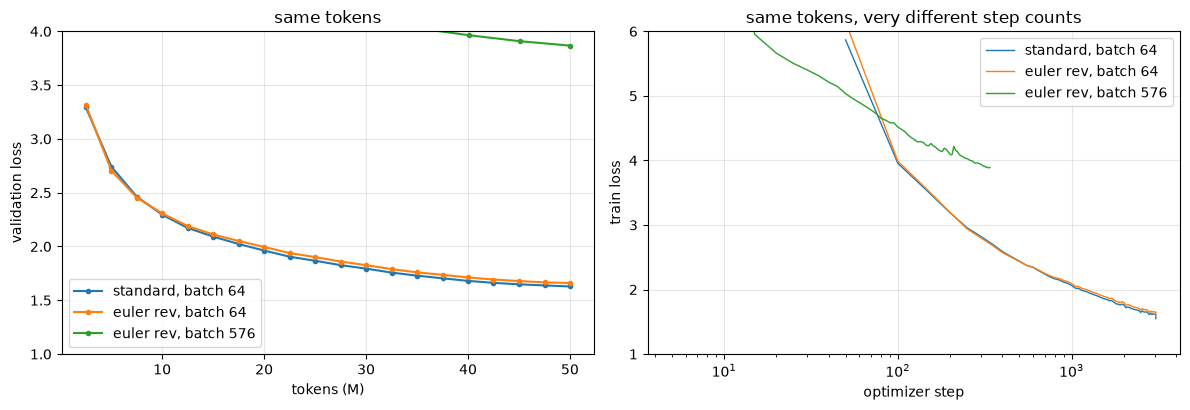

In [8]:
MB = R(f"maxbatch_{S['rule']}_rev")
r = row(MB); NUM["maxbatch_run"] = r
fixed = NUM["main"][f"{S['rule']} (reversible)"]
print(f"max-batch run: batch {r['batch']} ({r['batch']*256:,} tokens/step), {r['steps']} steps, peak lr {peak_lr(RunConfig(**{k: v for k, v in MB['config'].items() if k != 'notes'})):.2e}")
print(f"  val loss {r['val']:.4f} (fixed batch {fixed['val']:.4f}, {r['val']-fixed['val']:+.4f})")
print(f"  speed {r['tok_s']:.0f} tok/s (fixed batch {fixed['tok_s']:.0f}, x{r['tok_s']/fixed['tok_s']:.2f})")
print(f"  peak {r['peak_gib']:.2f} GiB (fixed batch {fixed['peak_gib']:.2f}); minutes {r['minutes']:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k, log in [("standard, batch 64", MAIN["standard"]), (f"{S['rule']} rev, batch 64", R(f"main_{S['rule']}_rev")),
               (f"{S['rule']} rev, batch {r['batch']}", MB)]:
    ev = log["evals"]
    ax[0].plot([e["tokens"] / 1e6 for e in ev], [e["val_loss"] for e in ev], marker="o", ms=3, label=k)
    tr = log["train"]
    ax[1].plot([t["step"] for t in tr], [t["loss"] for t in tr], label=k, lw=1)
ax[0].set(xlabel="tokens (M)", ylabel="validation loss", ylim=(1.0, 4.0), title="same tokens")
ax[1].set(xlabel="optimizer step", ylabel="train loss", xscale="log", ylim=(1.0, 6.0), title="same tokens, very different step counts")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "loss_max_batch.png", dpi=130); plt.show()

### Is the max-batch loss the batch size, or the learning rate?

At a fixed token budget, a 9× larger batch means 9× fewer optimizer steps, so some loss is expected. The check
below compares the runs **per step** instead of per token. If the large batch were only short of steps, then at
the same step it should be at least as good as batch 64, because each of its steps averages 9× more tokens.

Then a direct test of the learning rate: the same rule at batch 256, which fits without swapping, trained for 60
steps at three peak learning rates.

In [9]:
def loss_at_step(log, step):
    tr = log["train"]
    return min(tr, key=lambda t: abs(t["step"] - step))
e64 = R(f"main_{S['rule']}_rev")
print(f"{'step':>5s} {'batch 64 loss':>14s} {'batch '+str(MB['config']['batch'])+' loss':>15s}")
for st in (50, 100, 200, 300):
    a, b = loss_at_step(e64, st), loss_at_step(MB, st)
    print(f"{st:5d} {a['loss']:14.3f} {b['loss']:15.3f}")
spikes = [t for t in MB["train"] if t["gnorm"] > 10]
print("gradient-norm spikes > 10 in the max-batch run:", [(t["step"], f"{t['gnorm']:.1e}") for t in spikes])

from rev.experiments import LR_CHECK, LR_CHECK_BATCH
NUM["lrcheck"] = {}
for lr in LR_CHECK:
    log = R(f"lrcheck_{S['rule']}_b{LR_CHECK_BATCH}_lr{lr:g}")
    NUM["lrcheck"][lr] = dict(val=log["final_val_loss"], train=log["final_train_loss"], gnorm_max=max(t["gnorm"] for t in log["train"]))
    print(f"batch {LR_CHECK_BATCH}, 60 steps, peak lr {lr:g}: val loss {log['final_val_loss']:.3f}, max grad norm {NUM['lrcheck'][lr]['gnorm_max']:.2f}")

 step  batch 64 loss  batch 576 loss
   50          6.146           5.035
  100          3.987           4.516
  200          3.193           4.092
  300          2.800           3.943
gradient-norm spikes > 10 in the max-batch run: [(180, '4.8e+01'), (205, '9.5e+07')]
batch 256, 60 steps, peak lr 0.0015: val loss 4.637, max grad norm 2.20
batch 256, 60 steps, peak lr 0.003: val loss 5.182, max grad norm 2.13
batch 256, 60 steps, peak lr 0.006: val loss 4.926, max grad norm 1.79


### Throughput against batch size

The paper's speed gain comes entirely from the larger batch that the saved memory allows: 114.49 against 56.96
samples/s at batch 874 against 52. That only pays off if the device is underused at the small batch. The cell
below measures tokens/s against batch size here.

standard b=16: 13,324, b=64: 16,171, b=128: 16,960 tok/s
euler rev b=64: 13,468, b=128: 14,002, b=256: 5,555, b=384: 5,518, b=576: 5,429 tok/s


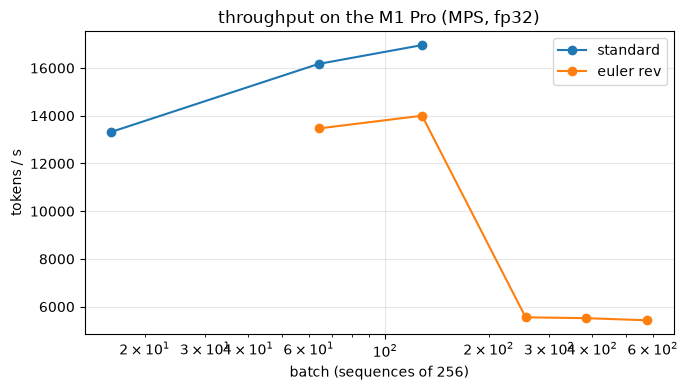

In [10]:
sizes_rev = sorted({64, 128, 256, 384, S["reversible"]["batch"]})
sizes_std = sorted({16, 64, 128, S["standard"]["batch"]})
tp = {"standard": [], f"{S['rule']} rev": []}
for b in sizes_std:
    tp["standard"].append((b, A.throughput(RunConfig(rule="standard", batch=b), steps=3)))
for b in sizes_rev:
    tp[f"{S['rule']} rev"].append((b, A.throughput(RunConfig(rule=S["rule"], reversible=True, h=S["h"], blend=S["blend"], batch=b), steps=2)))
for k, v in tp.items():
    print(k, ", ".join(f"b={b}: {t:,.0f}" for b, t in v), "tok/s")
NUM["throughput_vs_batch"] = tp
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in tp.items():
    ax.plot([b for b, _ in v], [t for _, t in v], marker="o", label=k)
ax.set(xscale="log", xlabel="batch (sequences of 256)", ylabel="tokens / s", title="throughput on the M1 Pro (MPS, fp32)")
ax.legend(); ax.grid(alpha=.3); fig.tight_layout(); fig.savefig(ART / "throughput_vs_batch.png", dpi=130); plt.show()

Both models fall off a cliff between batch 128 and 192, roughly 3× slower per token. The reversible model at
batch 192 uses only about 5 GiB, so this isn't memory or swap. The phase split shows it is the backward pass. Every
weight gradient is a matmul whose inner dimension is the number of tokens in the batch, and 128 × 256 = 32,768 = 2^15.
The cell below times the same matmul on either side of that size.

In [11]:
mm = {}
for K in (16384, 32768, 32769, 65536):
    a_ = torch.randn(384, K, device=DEV); b_ = torch.randn(K, 1536, device=DEV)
    a_ @ b_; torch.mps.synchronize(); t0 = __import__("time").perf_counter()
    for _ in range(5): a_ @ b_
    torch.mps.synchronize(); dt = (__import__("time").perf_counter() - t0) / 5
    mm[K] = 2 * 384 * 1536 * K / dt / 1e12
    print(f"(384 x {K}) @ ({K} x 1536): {mm[K]:.2f} TFLOP/s")
    del a_, b_
NUM["mps_matmul_tflops_by_inner_dim"] = mm
print(f"one token past 2^15 the MPS matmul is {mm[32768]/mm[32769]:.1f}x slower")

(384 x 16384) @ (16384 x 1536): 3.53 TFLOP/s
(384 x 32768) @ (32768 x 1536): 3.35 TFLOP/s


(384 x 32769) @ (32769 x 1536): 0.38 TFLOP/s


(384 x 65536) @ (65536 x 1536): 0.38 TFLOP/s
one token past 2^15 the MPS matmul is 8.8x slower


**What this means for the max-batch run.** Its 3.4k tok/s comes mostly from this MPS cliff, not from
reversibility. Swapping during that run made it somewhat worse: the throughput sweep above, run without swap,
gives about 5.5k at batch 576. On this backend, a batch above 128 sequences only keeps its speed if it is split
into micro-batches of at most 128 and the gradients are accumulated. But then the per-micro-batch memory is what
counts, and reversibility's memory saving no longer buys a larger batch. On a CUDA GPU, which is underused at small
batch, the paper's direction (bigger batch, more samples/s) is the expected one. This machine can't show it.

## 6. Memory against depth and sequence length

The course's central claim is that a reversible stack stores the same two boundary states however deep it is,
so its activation memory doesn't grow with depth. This section tests that by measuring each model's step peak:
- at batch 16, as the layer count goes from 2 to 32;
- at batch 4 and 10 layers, as the sequence length goes from 128 to 2,048.

In [12]:
depth = A.memory_sweep(RunConfig(batch=16), "n_layer", [2, 4, 8, 16, 32])
seq = A.memory_sweep(RunConfig(batch=4), "seq", [128, 256, 512, 1024, 2048])
NUM["memory_vs_depth"], NUM["memory_vs_seq"] = depth, seq

{'n_layer': 2, 'standard': 0.6980738639831543, 'midpoint_rev': 0.4802393913269043, 'euler_rev': 0.4860987663269043}


{'n_layer': 4, 'standard': 0.9720339775085449, 'midpoint_rev': 0.5198245048522949, 'euler_rev': 0.5261721611022949}


{'n_layer': 8, 'standard': 1.5194048881530762, 'midpoint_rev': 0.5992999076843262, 'euler_rev': 0.6048541069030762}


{'n_layer': 16, 'standard': 2.6157336235046387, 'midpoint_rev': 0.7573962211608887, 'euler_rev': 0.7631945610046387}


{'n_layer': 32, 'standard': 4.808391094207764, 'midpoint_rev': 1.0874104499816895, 'euler_rev': 1.0804858207702637}


{'seq': 128, 'standard': 0.41604089736938477, 'midpoint_rev': 0.34363245964050293, 'euler_rev': 0.34363245964050293}


{'seq': 256, 'standard': 0.6240153312683105, 'midpoint_rev': 0.35817766189575195, 'euler_rev': 0.3549380302429199}


{'seq': 512, 'standard': 1.161424160003662, 'midpoint_rev': 0.4489607810974121, 'euler_rev': 0.4584174156188965}


{'seq': 1024, 'standard': 2.4999136924743652, 'midpoint_rev': 0.6886305809020996, 'euler_rev': 0.7003493309020996}


{'seq': 2048, 'standard': 6.6420416831970215, 'midpoint_rev': 1.6314787864685059, 'euler_rev': 1.6547942161560059}


GiB added per extra layer (batch 16 x 256): {'standard': np.float64(0.137), 'midpoint_rev': np.float64(0.0202), 'euler_rev': np.float64(0.0198)}
training state per layer: 0.0198 GiB without gradients, 0.0264 GiB with them
standard: activations 75.5 bytes per token per hidden unit per layer (fp32); the course's count is 34 in 16-bit (~68 in fp32), plus the attention scores this MPS kernel keeps
midpoint_rev: 0.0202 GiB per layer = state without gradients + +0.47 MiB of activations: its peak is in the loss, before any gradient exists, and nothing per layer is stored
euler_rev: 0.0198 GiB per layer = state without gradients + +0.03 MiB of activations: its peak is in the loss, before any gradient exists, and nothing per layer is stored


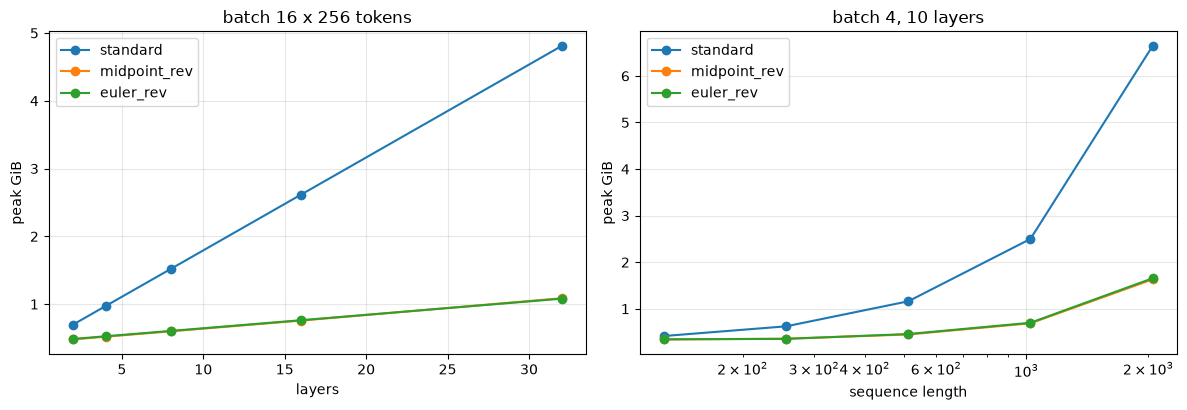

In [13]:
def slope(rows, axis, key):
    x = np.array([r[axis] for r in rows], float); yv = np.array([r[key] for r in rows])
    return np.polyfit(x, yv, 1)[0]
keys = ["standard", "midpoint_rev", "euler_rev"]
print("GiB added per extra layer (batch 16 x 256):", {k: round(slope(depth, "n_layer", k), 4) for k in keys})
# Training state also grows with depth: 12 d^2 weights per layer. Weights + Adam m, v = 12 bytes per weight in fp32,
# + 4 more once the gradients exist. Which of the two is resident at the peak depends on when the peak happens.
w_layer = 12 * 384 ** 2
s12, s16 = 12 * w_layer / GiB, 16 * w_layer / GiB
print(f"training state per layer: {s12:.4f} GiB without gradients, {s16:.4f} GiB with them")
act_std = slope(depth, "n_layer", "standard") - s16
print(f"standard: activations {act_std*GiB/(16*256*384):.1f} bytes per token per hidden unit per layer (fp32);"
      f" the course's count is 34 in 16-bit (~68 in fp32), plus the attention scores this MPS kernel keeps")
NUM["act_bytes_per_token_hidden_layer_std"] = act_std * GiB / (16 * 256 * 384)
for k in keys[1:]:
    print(f"{k}: {slope(depth, 'n_layer', k):.4f} GiB per layer = state without gradients "
          f"+ {(slope(depth, 'n_layer', k) - s12)*1024:+.2f} MiB of activations: its peak is in the loss, before any "
          f"gradient exists, and nothing per layer is stored")
NUM["rev_extra_mib_per_layer"] = {k: (slope(depth, "n_layer", k) - s12) * 1024 for k in keys[1:]}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k in keys:
    ax[0].plot([r["n_layer"] for r in depth], [r[k] for r in depth], marker="o", label=k)
    ax[1].plot([r["seq"] for r in seq], [r[k] for r in seq], marker="o", label=k)
ax[0].set(xlabel="layers", ylabel="peak GiB", title="batch 16 x 256 tokens")
ax[1].set(xlabel="sequence length", ylabel="peak GiB", xscale="log", title="batch 4, 10 layers")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "memory_vs_depth_seq.png", dpi=130); plt.show()

### Where the reversible model's peak goes

Once activations stop growing with depth, something else sets the peak. The course says the binding term moves.
At the fixed batch, I split the reversible model's peak into:
- the training state;
- the two boundary states;
- the output head's logits;
- whatever one layer needs while it is rebuilt and backpropagated.

Then I test whether computing the loss in chunks, so the logits are never all held at once, moves the peak.

In [14]:
B, T, d, V = FIXED_BATCH, 256, 384, 8192
state = NUM["params"] * 16                       # fp32: weight 4 + grad 4 + Adam m 4 + v 4
bound = 2 * B * T * d * 4
logits = B * T * V * 4
rule = S["rule"]
cfgr = RunConfig(rule=rule, reversible=True, h=S["h"], blend=S["blend"], batch=B)
full = measure_peak(cfgr); chunk = measure_peak(RunConfig(**{**cfgr.__dict__, "loss_chunk": 4096}))
print(f"{rule} reversible, batch {B}: measured peak {full/GiB:.2f} GiB; with chunked loss {chunk/GiB:.2f} GiB")
print(f"  training state (weights, grads, Adam)  {state/GiB:5.2f} GiB")
print(f"  two boundary states                     {bound/GiB:5.2f} GiB")
print(f"  loss: logits + log-softmax + gradient   {3*logits/GiB:5.2f} GiB  (3 x {logits/GiB:.2f})")
print(f"  left over                               {(full-state-bound-3*logits)/GiB:5.2f} GiB")
print(f"so the reversible peak is the loss. Chunked, the peak drops to {chunk/GiB:.2f} GiB and is now set by one layer's")
print(f"recompute-and-backward working set: {(chunk-state-bound)/GiB:.2f} GiB above state + boundary states")
NUM["breakdown"] = dict(peak=full/GiB, chunked=chunk/GiB, state=state/GiB, boundary=bound/GiB, logits=logits/GiB)

euler reversible, batch 64: measured peak 1.88 GiB; with chunked loss 1.01 GiB
  training state (weights, grads, Adam)   0.31 GiB
  two boundary states                      0.05 GiB
  loss: logits + log-softmax + gradient    1.50 GiB  (3 x 0.50)
  left over                                0.02 GiB
so the reversible peak is the loss. Chunked, the peak drops to 1.01 GiB and is now set by one layer's
recompute-and-backward working set: 0.65 GiB above state + boundary states


## 7. Reconstruction drift: how exact is "reversible" in fp32 and bf16?

The backward pass doesn't read stored activations; it rebuilds them. Any rounding in the inverse therefore feeds
the rebuilt state into the next inverse, and the error can grow down the stack.

The cells below take the trained weights and a validation batch, run each rule forward keeping every state, then
rebuild every state from the top two. They measure:
1. the rebuilt states' relative error, layer by layer, in fp32 and under bf16 autocast;
2. the reversible gradient against the stored-activation gradient on the same weights;
3. on untrained weights, how the error grows with depth for the pure midpoint, the blended midpoint and the
   Euler coupling.

midpoint fp32: rebuilt input rel.err 2.0e-05, worst state 2.0e-05, grad rel.err 2.0e-05, grad cosine 1.000000
midpoint bf16: rebuilt input rel.err 1.0e-01, worst state 1.0e-01, grad rel.err 1.3e-01, grad cosine 0.991532


euler    fp32: rebuilt input rel.err 4.6e-05, worst state 4.6e-05, grad rel.err 3.2e-05, grad cosine 1.000000
euler    bf16: rebuilt input rel.err 1.7e-01, worst state 1.7e-01, grad rel.err 1.5e-01, grad cosine 0.989409


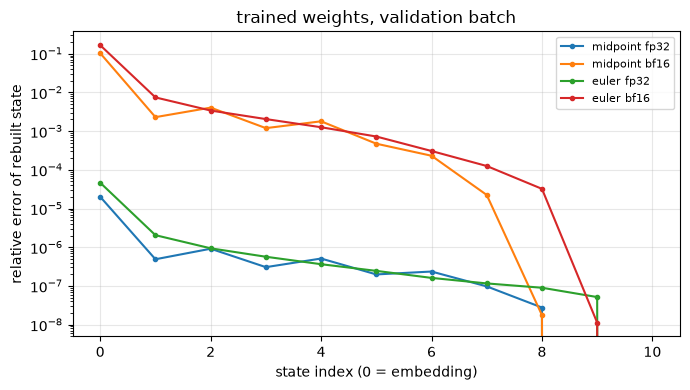

In [15]:
idx, y = (t.to(DEV) for t in A._batch(256, batch=8))
NUM["drift"] = {}
fig, ax = plt.subplots(figsize=(7, 4))
for rule in ("midpoint", "euler"):
    log = R(f"main_{rule}_rev")
    c = RunConfig(**{k: v for k, v in log["config"].items() if k != "notes"}).gpt()
    m = A.load_model(ROOT / "results" / f"main_{rule}_rev.pt", c, DEV)
    out = {}
    for amp in (False, True):
        e = A.reconstruction(m, idx, amp=amp)
        g = A.gradient_agreement(m, idx, y, amp=amp)
        out["bf16" if amp else "fp32"] = dict(worst_state=max(e), input_state=e[0], grad_rel_err=g["rel_err"], grad_cos=g["cos"])
        ax.semilogy(range(len(e)), e, marker="o", ms=3, label=f"{rule} {'bf16' if amp else 'fp32'}")
    NUM["drift"][rule] = out
    for k, v in out.items():
        print(f"{rule:8s} {k}: rebuilt input rel.err {v['input_state']:.1e}, worst state {v['worst_state']:.1e}, "
              f"grad rel.err {v['grad_rel_err']:.1e}, grad cosine {v['grad_cos']:.6f}")
    del m
ax.set(xlabel="state index (0 = embedding)", ylabel="relative error of rebuilt state", title="trained weights, validation batch")
ax.legend(fontsize=8); ax.grid(alpha=.3); fig.tight_layout(); fig.savefig(ART / "reconstruction_drift.png", dpi=130); plt.show()

In [16]:
idx_s = idx[:2]
rows = []
for L in (10, 20, 40, 80):
    r = {"layers": L}
    for name, rule, h, blend in [("midpoint a=1", "midpoint", 0.25, 1.0), ("midpoint a=0.5", "midpoint", 0.25, 0.5), ("euler", "euler", 0.5, 1.0)]:
        torch.manual_seed(0)
        m = GPT(GPTConfig(n_layer=L, rule=rule, h=h, blend=blend)).to(DEV)
        r[name] = A.reconstruction(m, idx_s)[0]
        del m
    rows.append(r)
    print(f"L={L:3d}  " + "  ".join(f"{k}: {v:.1e}" for k, v in r.items() if k != "layers"))
NUM["drift_vs_depth_init_fp32"] = rows

L= 10  midpoint a=1: 1.4e-06  midpoint a=0.5: 1.5e-04  euler: 9.4e-07


L= 20  midpoint a=1: 1.6e-06  midpoint a=0.5: 1.1e-01  euler: 1.0e-06


L= 40  midpoint a=1: 1.7e-06  midpoint a=0.5: 6.8e+04  euler: 1.1e-06


L= 80  midpoint a=1: 1.7e-06  midpoint a=0.5: 5.3e+16  euler: 1.2e-06


## 8. Overhead and cost

The course quotes the paper's estimate that reversibility costs 30–50% more per step. The extra work is one more
forward evaluation of every block during the backward pass. The cell below times the forward, backward and
optimizer phases at the fixed batch.

In [17]:
pt = {}
hm, am = chosen["midpoint"]; he, ae = chosen["euler"]
for name, cfgp in [("standard", RunConfig(rule="standard")), ("midpoint stored", RunConfig(rule="midpoint", h=hm, blend=am)),
                  ("midpoint reversible", RunConfig(rule="midpoint", reversible=True, h=hm, blend=am)),
                  ("euler reversible", RunConfig(rule="euler", reversible=True, h=he, blend=ae))]:
    pt[name] = A.phase_times(cfgp, steps=6, dev=DEV)
    p = pt[name]
    print(f"{name:20s} forward {p['forward']*1e3:6.0f} ms  backward {p['backward']*1e3:6.0f} ms  optimizer {p['optimizer']*1e3:5.0f} ms  "
          f"step {p['step']*1e3:6.0f} ms  {p['tok_per_s']:7.0f} tok/s")
base = pt["standard"]["step"]
for k in ("midpoint reversible", "euler reversible"):
    print(f"{k}: step time +{(pt[k]['step']/base-1)*100:.0f}% over standard; backward +{(pt[k]['backward']/pt['standard']['backward']-1)*100:.0f}%")
NUM["phase_times"] = pt

standard             forward    376 ms  backward    575 ms  optimizer    72 ms  step   1023 ms    16017 tok/s


midpoint stored      forward    389 ms  backward    588 ms  optimizer    71 ms  step   1048 ms    15633 tok/s


midpoint reversible  forward    253 ms  backward    935 ms  optimizer    70 ms  step   1257 ms    13030 tok/s


euler reversible     forward    242 ms  backward    912 ms  optimizer    70 ms  step   1224 ms    13385 tok/s
midpoint reversible: step time +23% over standard; backward +63%
euler reversible: step time +20% over standard; backward +59%


In [18]:
# Cost of each 50M-token run, in device-hours on this machine and relative to the standard run.
print(f"{'run':30s} {'hours':>6s} {'relative cost':>13s}")
base_h = NUM["main"]["standard"]["minutes"] / 60
cost = {}
for k, r in list(NUM["main"].items()) + [(f"{S['rule']} reversible, max batch", NUM["maxbatch_run"])]:
    hrs = r["minutes"] / 60
    cost[k] = dict(hours=hrs, relative=hrs / base_h)
    print(f"{k:30s} {hrs:6.2f} {hrs/base_h:13.2f}")
NUM["cost"] = cost
print("At a cloud price P per GPU-hour each run costs hours x P; the ratios carry over only if the cloud GPU has the same")
print("speed-vs-batch curve as this one (Section 5), which a large GPU usually doesn't: it is underused at batch 64.")

run                             hours relative cost
standard                         0.86          1.00
midpoint (reversible)            1.06          1.23
euler (reversible)               1.05          1.21
euler reversible, max batch      4.06          4.69
At a cloud price P per GPU-hour each run costs hours x P; the ratios carry over only if the cloud GPU has the same
speed-vs-batch curve as this one (Section 5), which a large GPU usually doesn't: it is underused at batch 64.


## 9. Summary

The README discusses these results; every number in it comes from `submission_artifacts/s13_numbers.json`, which
the cell below writes.

In [19]:
print(f"{'run':36s} {'batch':>6s} {'val loss':>9s} {'train loss':>10s} {'tok/s':>7s} {'peak GiB':>9s}")
summary = list(NUM["main"].items()) + [(f"{S['rule']} reversible, max batch", NUM["maxbatch_run"])]
for k, r in summary:
    print(f"{k:36s} {r['batch']:6d} {r['val']:9.4f} {r['train']:10.4f} {r['tok_s']:7.0f} {r['peak_gib']:9.2f}")
(ART / "s13_numbers.json").write_text(json.dumps(NUM, indent=1, default=float))
print("saved", ART / "s13_numbers.json")

run                                   batch  val loss train loss   tok/s  peak GiB
standard                                 64    1.6017     1.5491   16068      6.47
midpoint (reversible)                    64    1.6497     1.5984   13067      1.85
euler (reversible)                       64    1.6383     1.5906   13244      1.88
euler reversible, max batch             576    3.8654     3.8900    3413     15.00
saved /Users/pradeep/AL/ERAv5/s13/submission_artifacts/s13_numbers.json
